# Introduction

In this tutorial, we demonstrate how to use **SpatialZoomer** to identify multi-scale spatial structures in single-cell resolved spatial transcriptomics (ST) data, ranging from cells to niches and tissue domains.  

For illustration, we use an officially provided cell-segmented Stereo-seq mouse brain sample (50,140 cells, 25,879 genes). Stereo-seq is a sequencing-based, high-resolution ST technology. The recorded analysis took approximately 20 minutes.

#### Table of Contents
- [0. Installation, package loading, and data preprocessing](#0-installation-package-loading-and-data-preprocessing)
- [1. Extract multi-scale features via spectral graph signal processing](#1-extract-multi-scale-features-via-spectral-graph-signal-processing)
- [2. Identify critical scales automatically](#2-identify-critical-scales-automatically)
- [3. Identify spatial structures using two-step clustering](#3-identify-spatial-structures-using-two-step-clustering)
  - [Results and Analysis](#results-and-analysis)
  - [Results in the save_path Folder](#results-in-the-save_path-folder)

### 0. Installation, package loading, and data preprocessing

For detailed installation instructions, environment setup, and package dependencies, please refer to the [SpatialZoomer GitHub repository](https://github.com/Li-Xinqi/SpatialZoomer.git).

Install or upgrade to the latest version of SpatialZoomer:

```bash
python -m pip install --upgrade spatialzoomer
```

Import the installed package:

```python
import spatialzoomer as sz
```

Next, load the spatial transcriptomics data, perform gene-level quality control, and normalize the expression matrix.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import squidpy as sq
import seaborn as sns
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,     
    "savefig.dpi": 300      
    })
use_dpi = 80 

Please set the following basic information:
* `runLabel`: The name of the dataset.

* `save_path`: A path to save the analysis results.

* `adata`: An **AnnData** object storing the officially provided cell-segmented Stereo-seq mouse brain data,  

  - `adata.X` contains the raw, unnormalized transcript count matrix.  
  
  - `adata.obsm['spatial']` stores the spatial coordinates.  
 
The **input ST data** in AnnData format are available in the current Zenodo archive and can also be downloaded from [Google Drive](https://drive.google.com/file/d/1jMOzj1Hta45B3GtRuAKa_CPO-9WtpsYE/view?usp=drive_link).

The original data can be downloaded from the [official Stereo-seq dataset page](https://en.stomics.tech/col1311/index.html).

In [2]:
runLabel = 'Mouse_brain_cell_bin'
save_path = './Outputs/' + runLabel+'_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata = sc.read_h5ad("./" + runLabel+ ".h5ad")
adata

AnnData object with n_obs × n_vars = 50140 × 25879
    obs: 'annotation'
    var: 'Gene'
    uns: 'annotation_colors'
    obsm: 'spatial'
    layers: 'counts'

<Axes: title={'center': 'Unique transcripts per cell'}, xlabel='n_genes_by_counts', ylabel='Count'>

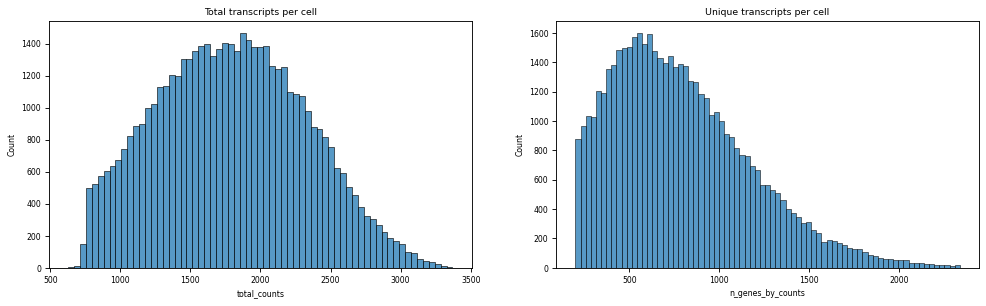

In [3]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

fig, axs = plt.subplots(1, 2, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)


**Quality control and normalization**

* `filter_genes` removes genes detected in too few cells;
* `sz.Preprocess` stores the original count matrix in `adata.layers["counts"]`, performs total-count normalization, and applies a log(1+x) transformation.

In [4]:
# Quality control on genes
sc.pp.filter_genes(adata, min_cells = 5)

# Normalization
adata = sz.Preprocess(adata)
adata

AnnData object with n_obs × n_vars = 50140 × 22222
    obs: 'annotation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes'
    var: 'Gene', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'annotation_colors', 'log1p'
    obsm: 'spatial'
    layers: 'counts'

### 1. Extract multi-scale features via spectral graph signal processing

- Obtain **graph signals** (cell programs) from transcriptomic data using dimensionality reduction with **NMF**.  

- Construct a **spatial neighbor graph** based on the physical proximity of cells.  

- Apply a bank of **heat-kernel-based low-pass filters** to extract features across multiple spatial scales.

Perform NMF to obtain graph signals. `n_components` specifies the dimensionality of the graph signals.

In [5]:
adata = sz.performDR(adata, type = 'NMF', n_components=50)
adata

Time taken to perform NMF: 296.8575 seconds


AnnData object with n_obs × n_vars = 50140 × 22222
    obs: 'annotation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes'
    var: 'Gene', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'annotation_colors', 'log1p'
    obsm: 'spatial', 'X_nmf'
    varm: 'nmf_loadings'
    layers: 'counts'

Initialize the SpatialZoomer object and define a set of candidate scales.

In [6]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path)
 
scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

In [7]:
sz_analyzer.dpi = use_dpi

Perform spectral graph signal processing to extract multi-scale features:

- `use_rep`: selects graph signals from `adata.obsm`; here we use `X_nmf` (NMF-transformed data)

- `n_neighbors`: number of neighbors in the spatial neighbor graph

- `scales`: candidate scales defined above

In [8]:
sz_analyzer.multiscale_transform(use_rep='X_nmf', n_neighbors=10, scales=scales)

Median similarities:  4.999999999990372
Time taken to construct spatial_knn: 0.2474 seconds
Time taken to perform spectral graph filter bank: 21.1490 seconds
Transformed signals saved to ./Outputs/Mouse_brain_cell_bin_SpatialZoomer//Mouse_brain_cell_bin_transformed_signals.h5


### 2. Identify critical scales automatically

SpatialZoomer partitions the cross-scale similarity map into contiguous blocks and automatically selects critical scales representing the transitions and centers of these blocks.

- `max_clusters` and `min_clusters` specify the range of possible block numbers. Within this range, the Elbow method determines the optimal number of blocks.

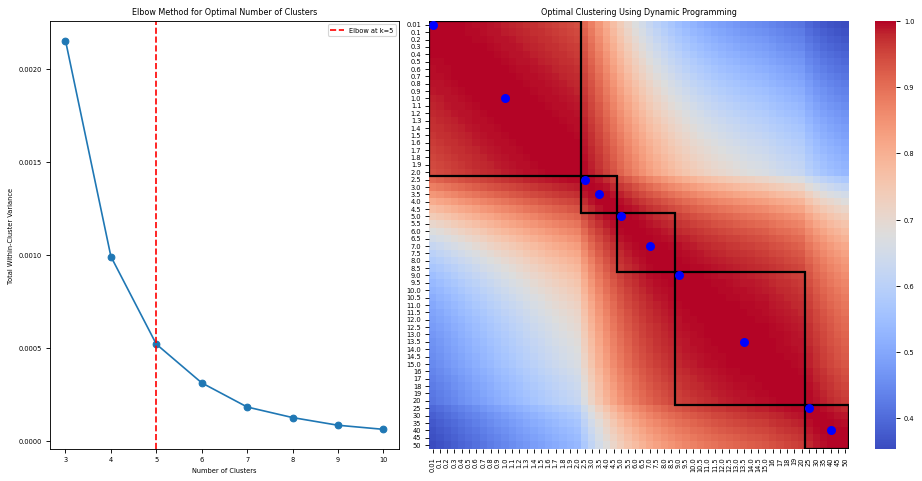

The optimal number of clusters is: 5
Typical scales: [0.01, 1.0, 2.5, 3.5, 5.0, 7.0, 9.0, 13.5, 25, 40]
Time taken to perform identification of typical scales: 6.4774 seconds


In [9]:
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)

### 3. Identify spatial structures using two-step clustering

Clustering is performed in two steps:

1. **Mini-Batch K-Means** is applied to the transformed signals at each selected scale to obtain 10,000 metacells.

2. **Leiden clustering** is applied to the metacells. A higher resolution yields more clusters.

**Recommendation:** test multiple resolution values and select the setting that matches biological expectations and downstream tasks.

In [10]:
resolutions = [0.8, 1, 1.2]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions)

Time taken to perform UMAP and clustering for raw signal: 164.5649 seconds
Time taken to perform clustering for signal at scale 0.01: 79.4802 seconds
Time taken to perform clustering for signal at scale 1.0: 80.3159 seconds
Time taken to perform clustering for signal at scale 2.5: 78.8632 seconds
Time taken to perform clustering for signal at scale 3.5: 75.8071 seconds
Time taken to perform clustering for signal at scale 5.0: 71.9692 seconds
Time taken to perform clustering for signal at scale 7.0: 65.7418 seconds
Time taken to perform clustering for signal at scale 9.0: 74.8154 seconds
Time taken to perform clustering for signal at scale 13.5: 76.5635 seconds
Time taken to perform clustering for signal at scale 25.0: 74.5422 seconds
Time taken to perform clustering for signal at scale 40.0: 71.9933 seconds
Total time: 750.2602 seconds


The clustering and UMAP results at each critical scale are stored in `sz_analyzer.adata`.

- **Clustering results** are stored in `sz_analyzer.adata.obs`, with keys formatted as `leiden_<scale>_res<resolution>`.

- **UMAP embeddings** are stored in `sz_analyzer.adata.obsm`, with keys formatted as `X_umap_<scale>`.

In [11]:
sz_analyzer.adata

AnnData object with n_obs × n_vars = 50140 × 22222
    obs: 'annotation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'Kmeans_Raw', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'leiden_Raw_res1.2', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'leiden_scale0.01_res1.2', 'Kmeans_scale1.0', 'leiden_scale1.0_res0.8', 'leiden_scale1.0_res1', 'leiden_scale1.0_res1.2', 'Kmeans_scale2.5', 'leiden_scale2.5_res0.8', 'leiden_scale2.5_res1', 'leiden_scale2.5_res1.2', 'Kmeans_scale3.5', 'leiden_scale3.5_res0.8', 'leiden_scale3.5_res1', 'leiden_scale3.5_res1.2', 'Kmeans_scale5.0', 'leiden_scale5.0_res0.8', 'leiden_scale5.0_res1', 'leiden_scale5.0_res1.2', 'Kmeans_scale7.0', 'leiden_scale7.0_res0.8', 'leiden_scale7.0_res1', 'leiden_scale7.0_res1.2', 'Kmeans_scale9.0', 'leiden_scale9.0_res0.8', 'leiden_scale9.0_res1', '

### Results and Analysis

- In the **raw signal space** (Scale 0.0), clustering reflects the single-cell scale, enabling the identification of cell types or states.

- **As the scale increases**, each cell progressively integrates spatial context from broader neighborhoods, capturing spatial structures such as niches and tissue domains.

- At excessively large scales, signals become over-smoothed and may no longer preserve meaningful biological distinctions.

Note: Results may slightly differ from those reported in the paper because NMF, Leiden, and UMAP involve randomness. Although random seeds are set, minor variations can still occur across environments or devices.

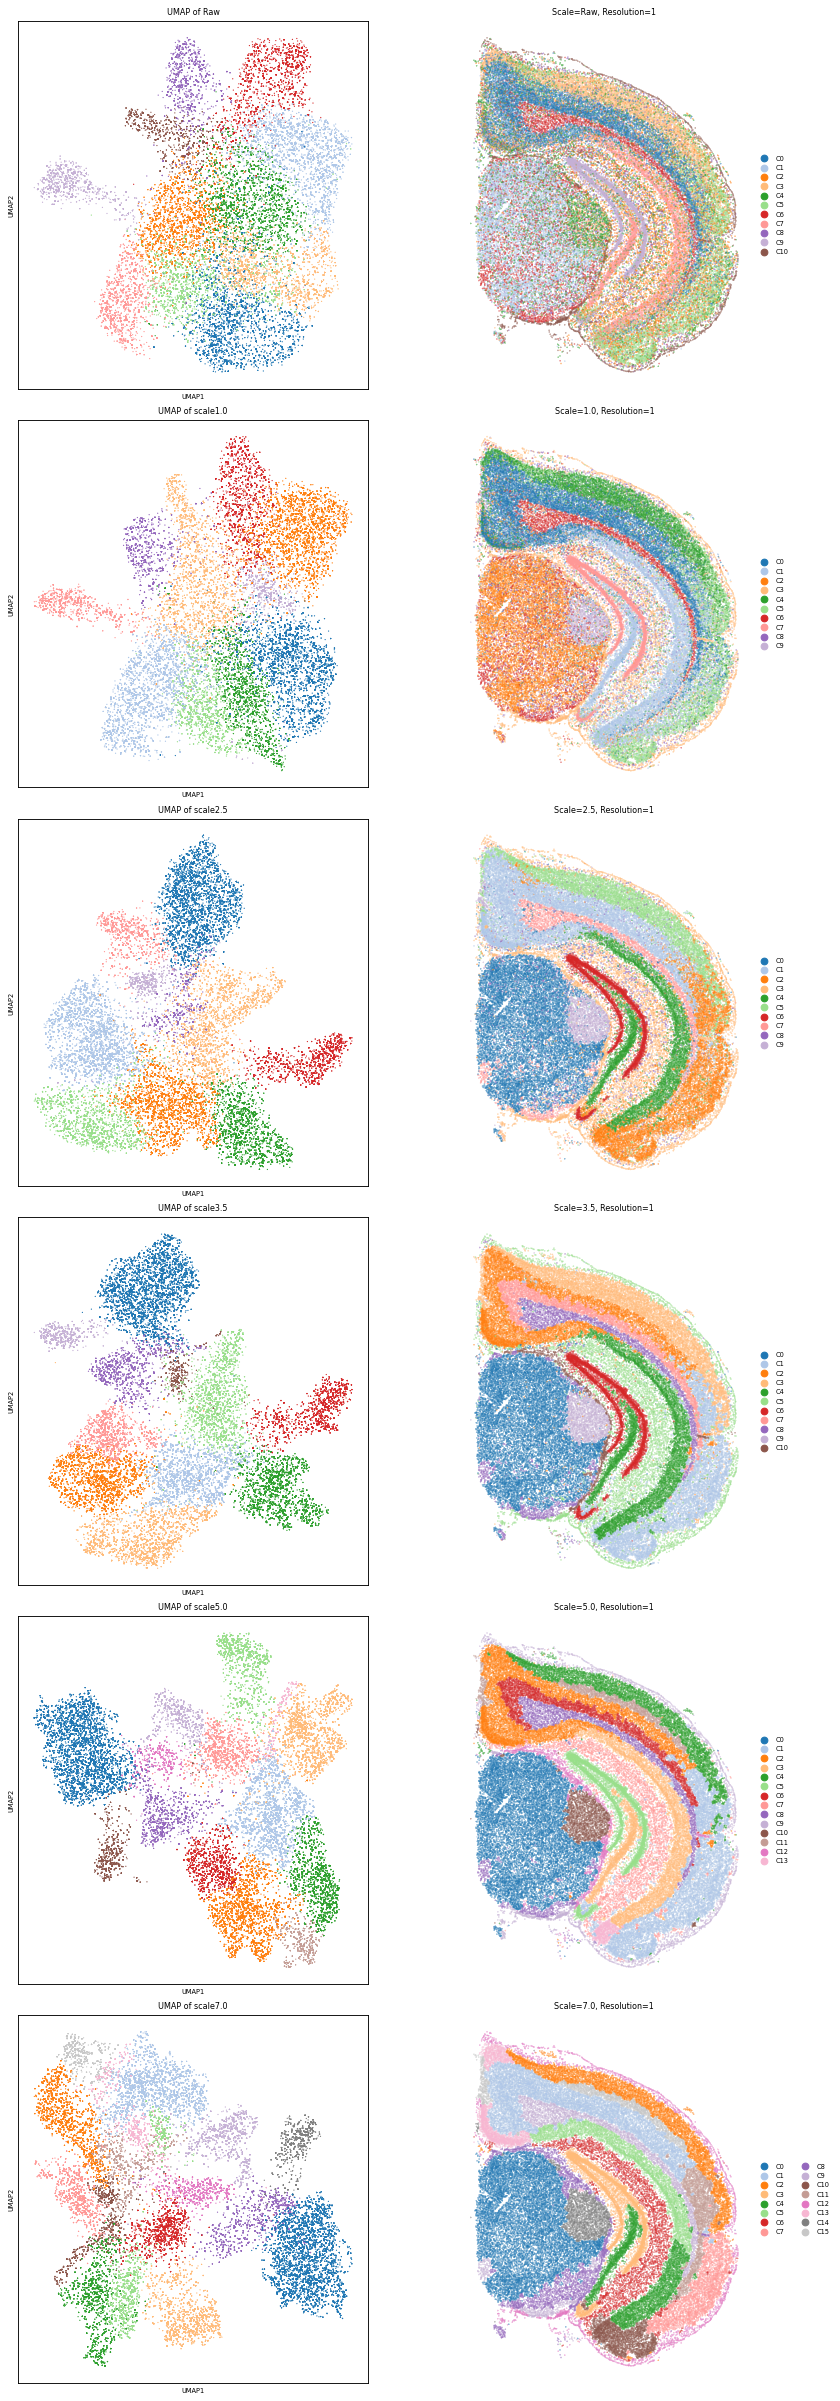

In [12]:
sz_analyzer.plot_multiscale_clusters(resolution=1, figsize=(12, 30), pt_size_scatter= 0.1, min_scale = 0.5, max_scale = 8)

Quantify the contributions of spatial proximity and transcriptomic similarity to clustering outcomes across different scales.

Median similarities:  4.999999997628734
Time taken to construct expr_knn: 0.5945 seconds


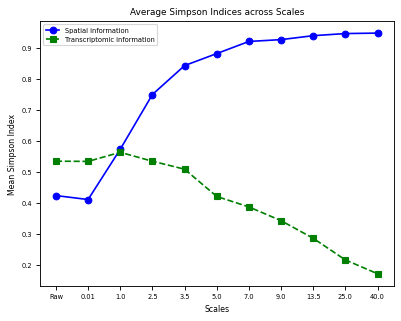

In [13]:
sz_analyzer.plot_simpson()

The `sz_analyzer.adata` object is compatible with the Python ecosystem for scRNA-seq and ST data, including packages such as **scanpy** and **squidpy**, and can be used directly for downstream analysis and visualization.

In [14]:
sz_analyzer.adata.write(save_path + runLabel + '_SpatialZoomer.h5ad')

### Results in the `save_path` folder

The following output files are generated and saved in the `save_path` directory:

- `<runLabel>_SpatialZoomer.h5ad`: The core AnnData object containing all multi-scale clustering results, recommended for downstream analyses.

- `<runLabel>_transformed_signals.h5`: Multi-scale features extracted by the spectral graph filter bank.

- `Typical_scales.pdf`: Visualization of critical scale selection.

- `Typical_scales.csv`: Table recording the selected critical scales.

- `<runLabel>_object_kmeans_<critical scale>.h5ad`: Intermediate K-Means results at each critical scale.

- `Average_Simpson_Indices_across_Scales.pdf`: Contributions of spatial proximity and transcriptomic similarity across scales.